# Session 2: Geometric Examples, Odd Odds and a Rocket

*ECE 225A, Module 02 (Binomial and Geometric Applications), deck 3.Geometric_examples, slides 1-9*

Module 01 derived the geometric distribution $G_p$: its PMF $q^{n-1}p$, its tail $q^n$, and its memorylessness. This session uses it twice. First, a coin game shows that going first is worth a lot, and computing the advantage reduces to asking how likely a geometric variable is to be odd. Second, a rocket program asks how risky a crewed flight is when the mishap probability is unknown. Calculus gives a bound that holds for every $p$, which is a good example of how much can be deduced with very few assumptions.

The title slide of this deck also lists "How to succeed without memory" and "Goldman Sachs", but the PDF has no slides on them, so they are not covered here.

## Learning objectives

After this session you should be able to:

1. Translate a turn-based game into a parity question about a geometric variable.
2. Compute $P(X \text{ odd}) = 1/(2 - p)$ for $X \sim G_p$ in two ways: with a geometric series, and by relating odd to even.
3. Sanity check a formula with inequalities, limits, and monotonicity.
4. Set up a test-then-fly program as the event $X = n$, and maximize $P(X = n)$ over $p$ with calculus.
5. Use the bound $P(X = n) \lesssim \frac{1}{e(n - 1)}$, and explain what it does and does not guarantee.

## Prerequisites

- Geometric PMF, tail, and memorylessness (Module 01, Session 5).
- The geometric series $\sum_{i \ge 0} r^i = 1/(1 - r)$.
- Calculus: the product rule, finding extrema, and the limit $(1 - 1/n)^n \to 1/e$.

In [1]:
from fractions import Fraction
from math import e

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, v):
    # Print an exact value as a fraction and as a decimal.
    print(f"{label}: {v} = {float(v):.6f}")

## 1. The head start game (slide 2)

**Intuition.** Alice and Bob take turns flipping a fair coin, with Alice going first, and whoever gets the first heads wins. Alice has an obvious advantage, since she gets a chance to win before Bob flips at all. How large is it?

**Key observation.** Forget who is flipping and watch the sequence of flips. Alice flips on turns 1, 3, 5, and so on, while Bob flips on turns 2, 4, 6, and so on. So

$$\text{Alice wins} \iff \text{the first heads appears on an odd flip}.$$

For example, the sequence $t, t, h$ ends on flip 3 and Alice wins, while $t, t, t, h$ ends on flip 4 and Bob wins. The number of flips up to the first heads is geometric, so the game reduces to a question about parity.

## 2. Odd odds (slide 3)

**Question.** For $X \sim G_p$ with $p > 0$, what is $P(X \text{ is odd})$, that is, $P(X \in \lbrace 1, 3, 5, \dots \rbrace)$?

**Way 1: direct sum.** The PMF is $P(X = k) = q^{k-1}p$, so

$$P(\text{odd}) = P(1) + P(3) + P(5) + \cdots = p + q^2 p + q^4 p + \cdots = p\,(1 + q^2 + q^4 + \cdots) = \frac{p}{1 - q^2}.$$

Factor $1 - q^2 = (1 - q)(1 + q) = p(1 + q)$. The $p$ cancels, leaving

$$P(\text{odd}) = \frac{1}{1 + q} = \frac{1}{2 - p}.$$

**Way 2: relate odd to even.** Compare the two series term by term:

$$P(\text{odd}) = p + q^2 p + q^4 p + \cdots, \qquad P(\text{even}) = qp + q^3 p + q^5 p + \cdots = q \cdot P(\text{odd}).$$

These two events cover everything, so

$$1 = P(\text{odd}) + P(\text{even}) = P(\text{odd}) \cdot (1 + q), \qquad \text{which gives} \quad P(\text{odd}) = \frac{1}{1 + q} = \frac{1}{2 - p}.$$

Way 2 needs no infinite sum at all, only the fact that every term of the even series is $q$ times a term of the odd series.

In [2]:
for p in [Fraction(1, 2), Fraction(1, 6), Fraction(1, 10), Fraction(9, 10)]:
    q = 1 - p
    partial = sum(q ** (k - 1) * p for k in range(1, 400, 2))
    print(f"p = {str(p):>4}: 1/(2 - p) = {str(1 / (2 - p)):>6} = {float(1 / (2 - p)):.6f}, partial sum {float(partial):.6f}")

X = rng.geometric(0.3, size=1_000_000)
print(f"\nsimulated p = 0.3: P(odd) = {np.mean(X % 2 == 1):.4f}, formula {1 / 1.7:.4f}")

p =  1/2: 1/(2 - p) =    2/3 = 0.666667, partial sum 0.666667
p =  1/6: 1/(2 - p) =   6/11 = 0.545455, partial sum 0.545455
p = 1/10: 1/(2 - p) =  10/19 = 0.526316, partial sum 0.526316
p = 9/10: 1/(2 - p) =  10/11 = 0.909091, partial sum 0.909091

simulated p = 0.3: P(odd) = 0.5880, formula 0.5882


## 3. Who wins the head start game? (slide 4)

Apply the result with a fair coin, $p = 1/2$:

$$P(\text{Alice wins}) = \frac{1}{2 - p} = \frac{1}{1.5} = \frac{2}{3}.$$

Going first doubles the odds: Alice wins twice as often as Bob.

In [3]:
flips = rng.geometric(0.5, size=1_000_000)
show("exact", Fraction(2, 3))
print(f"simulated: {np.mean(flips % 2 == 1):.6f}")

exact: 2/3 = 0.666667
simulated: 0.667273


## 4. Sanity checks (slide 5)

A formula is worth trusting only after it passes some tests that do not rely on the derivation.

**Does going first help?** It should, and it does: $2 - p < 2$, so $P(\text{Alice}) = \frac{1}{2 - p} > \frac{1}{2}$.

**Limits and direction.**

| $p$ | $P(\text{Alice})$ | Why it makes sense |
|---|---|---|
| $\to 1$ | $\to 1$ | Alice's first flip almost surely wins |
| $\to 0$ | $\to 1/2$ | the game lasts so long that the head start stops mattering |
| increases | increases | a likely success makes the first turn more valuable |

**Quiz.** Show that $\dfrac{1}{2 - p} \ge p$ for $0 < p \le 1$. Here are two proofs.

- *Algebra ("muscle").* Since $p(2 - p) = (1 - q)(1 + q) = 1 - q^2 \le 1$, dividing by $2 - p$ gives the claim.
- *Probability ("elegance").* For $X \sim G_p$, we have $p = P(X = 1) \le P(X \text{ odd}) = \frac{1}{2 - p}$, since 1 is one of the odd numbers.

The second proof requires no algebra and explains why the inequality holds.

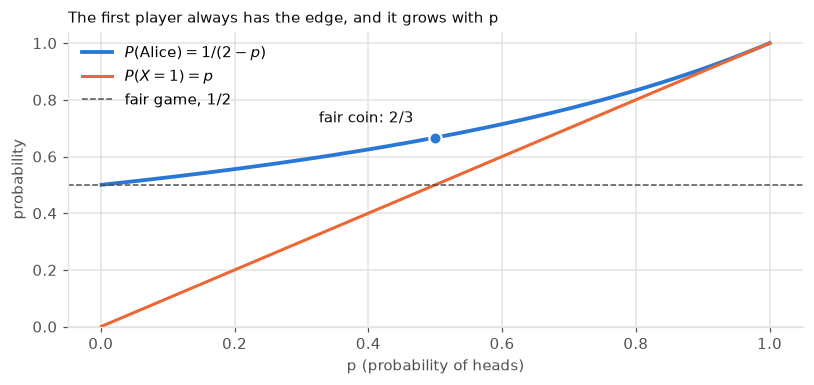

In [4]:
ps = np.linspace(0.001, 1, 400)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ps, 1 / (2 - ps), color=BLUE, lw=2.5, label="$P(\\mathrm{Alice}) = 1/(2 - p)$")
ax.plot(ps, ps, color=ORANGE, lw=2, label="$P(X = 1) = p$")
ax.axhline(0.5, color=MUTED, lw=1, ls="--", label="fair game, 1/2")
ax.plot([0.5], [2 / 3], "o", color=BLUE, ms=8, mec="white", mew=1.5)
ax.annotate("fair coin: 2/3", (0.5, 2 / 3), textcoords="offset points", xytext=(-14, 10), color=INK, ha="right")
ax.set(xlabel="p (probability of heads)", ylabel="probability", ylim=(0, 1.04))
ax.legend(frameon=False, loc="upper left")
ax.set_title("The first player always has the edge, and it grows with p", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 5. NASA's new rocket: the setup (slides 6-7)

**The plan.** A new rocket is tested up to 10 times. If no test has a serious mishap, it then flies a crew once. A *catastrophe* is a serious mishap on the crewed flight. What is the probability of a catastrophe?

**Assumptions.** Every flight has the same mishap probability $p_{\text{mh}}$, and flights are independent. Start with $p_{\text{mh}} = 0.01$.

**Model.** Let $X$ be the flight of the first mishap, so $X \sim G_{0.01}$. A catastrophe requires that the first ten flights are clean and that flight 11 fails, which is exactly $X = 11$:

$$P(\text{catastrophe}) = P(X = 11) = 0.99^{10} \cdot 0.01 \approx 0.009.$$

**The real problem.** Nobody knows $p_{\text{mh}}$, and a new rocket gives no data to estimate it. Can we bound the probability of a catastrophe without knowing $p_{\text{mh}}$?

Note that very risky rockets are not the most dangerous for the crew: if $p_{\text{mh}}$ is large, a mishap almost surely happens during testing, and the crew never flies.

In [5]:
for p_mh in [0.001, 0.01, 0.05, 1 / 11, 0.2, 0.5]:
    print(f"p_mh = {p_mh:.4f}: P(X = 11) = {(1 - p_mh) ** 10 * p_mh:.5f}")

sim = rng.geometric(0.01, size=2_000_000)
print(f"\nsimulated at p_mh = 0.01: {np.mean(sim == 11):.5f}")

p_mh = 0.0010: P(X = 11) = 0.00099
p_mh = 0.0100: P(X = 11) = 0.00904
p_mh = 0.0500: P(X = 11) = 0.02994
p_mh = 0.0909: P(X = 11) = 0.03505
p_mh = 0.2000: P(X = 11) = 0.02147
p_mh = 0.5000: P(X = 11) = 0.00049

simulated at p_mh = 0.01: 0.00911


## 6. The highest catastrophe probability (slide 8)

**Setup.** For a fixed $n \ge 2$, treat the probability as a function of $p$:

$$f(p) = P(X = n) = q^{n-1}p = (1 - p)^{n-1}p.$$

**Derivative.** By the product rule,

$$f'(p) = (1 - p)^{n-1} - (n - 1)(1 - p)^{n-2}p.$$

**Extrema.** Set $f'(p) = 0$ and divide by $(1 - p)^{n-2}$:

$$1 - p = (n - 1)p, \qquad \text{so} \qquad p = \frac{1}{n}.$$

This is the only extremum inside $(0, 1)$. Since $f(p) \to 0$ as $p \to 0$ and as $p \to 1$, while $f$ is positive in between, it is the **global maximum**.

**The maximum value.** Substitute $p = 1/n$ and rewrite to expose a familiar limit:

$$\max_p P(X = n) = \frac{(1 - 1/n)^{n-1}}{n} = \frac{(1 - 1/n)^n}{(1 - 1/n)\, n} = \frac{(1 - 1/n)^n}{n - 1} \lesssim \frac{1}{e(n - 1)},$$

using $(1 - 1/n)^n \to 1/e$. The sequence $(1 - 1/n)^n$ increases toward $1/e$ from below, so the last step is a true inequality for every $n \ge 2$.

**Result for the rocket.** With $n = 11$, for every value of $p$,

$$P(X = 11) \le \frac{1}{10e} \approx 0.037.$$

Whatever the rocket's actual reliability, the probability of a catastrophe is at most about 3.7%. The worst case is $p = 1/11$, which gives $0.0350$.

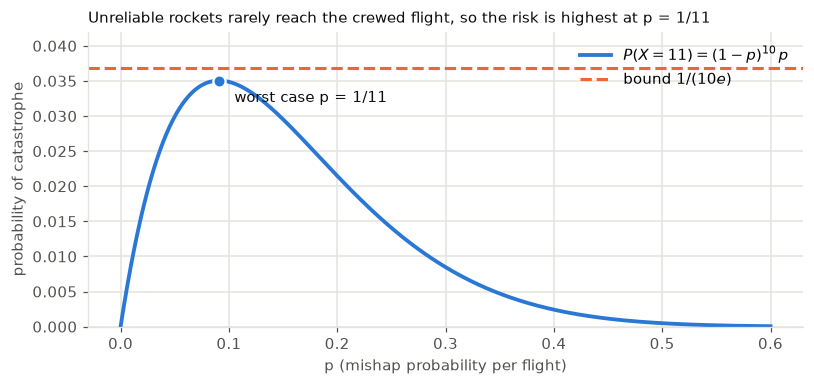

In [6]:
ps = np.linspace(0, 0.6, 600)
f = (1 - ps) ** 10 * ps

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ps, f, color=BLUE, lw=2.5, label="$P(X = 11) = (1 - p)^{10}\\, p$")
ax.axhline(1 / (10 * e), color=ORANGE, lw=2, ls="--", label="bound $1/(10e)$")
ax.plot([1 / 11], [(10 / 11) ** 10 / 11], "o", color=BLUE, ms=8, mec="white", mew=1.5)
ax.annotate("worst case p = 1/11", (1 / 11, (10 / 11) ** 10 / 11), textcoords="offset points", xytext=(10, -14), color=INK)
ax.set(xlabel="p (mishap probability per flight)", ylabel="probability of catastrophe", ylim=(0, 0.042))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Unreliable rockets rarely reach the crewed flight, so the risk is highest at p = 1/11", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [7]:
print(" n   argmax p     exact maximum    bound 1/(e(n-1))")
for n in [2, 5, 11, 21, 38, 101]:
    grid = np.linspace(1e-4, 1, 200_001)
    vals = (1 - grid) ** (n - 1) * grid
    exact = (1 - 1 / n) ** (n - 1) / n
    print(f"{n:3d}   {grid[vals.argmax()]:.5f}      {exact:.6f}         {1 / (e * (n - 1)):.6f}")

 n   argmax p     exact maximum    bound 1/(e(n-1))
  2   0.50000      0.250000         0.367879
  5   0.20000      0.081920         0.091970
 11   0.09091      0.035049         0.036788
 21   0.04762      0.017947         0.018394
 38   0.02632      0.009810         0.009943
101   0.00990      0.003661         0.003679


## 7. Pros, cons, and the moral (slide 9)

**The good news.**

- The bound holds with no knowledge of $p_{\text{mh}}$.
- We can make it as small as we like by adding test flights, since it falls as $\frac{1}{e(n - 1)}$.

**The bad news.**

- The decay is slow. To bring the bound down to 1%, we need $\frac{1}{e \cdot t} \le 0.01$, or about $t = 37$ test flights.
- The bound covers only one crewed flight. The risk grows with each later crewed flight.

We can quantify the last point. If the crew flies $k$ times after $t$ clean tests, then a catastrophe has probability $q^t(1 - q^k)$, and its worst case over $q$ grows quickly with $k$. Exercise 9 derives the formula. With $t = 10$ tests and $k = 10$ crewed flights, the worst case is $1/4$.

**The moral.** Theory can extract strong conclusions from very few assumptions. Here, one line of calculus removed the need to know $p_{\text{mh}}$ at all. Still, this is no substitute for good engineering: the bound rests on identical and independent flights, and it says nothing about making the rocket better.

In [8]:
for t in [10, 36, 37, 38]:
    print(f"t = {t:2d} tests: bound 1/(e t) = {1 / (e * t):.5f}, exact worst case = {(t / (t + 1)) ** t / (t + 1):.5f}")

t = 10
qs = np.linspace(0, 1, 100_001)
print("\nworst-case catastrophe probability after 10 tests:")
for k in [1, 2, 5, 10, 20]:
    print(f"  {k:2d} crewed flights: {(qs ** t * (1 - qs ** k)).max():.4f}")

t = 10 tests: bound 1/(e t) = 0.03679, exact worst case = 0.03505
t = 36 tests: bound 1/(e t) = 0.01022, exact worst case = 0.01008
t = 37 tests: bound 1/(e t) = 0.00994, exact worst case = 0.00981
t = 38 tests: bound 1/(e t) = 0.00968, exact worst case = 0.00956

worst-case catastrophe probability after 10 tests:
   1 crewed flights: 0.0350
   2 crewed flights: 0.0670
   5 crewed flights: 0.1481
  10 crewed flights: 0.2500
  20 crewed flights: 0.3849


## Common pitfalls

1. **Assuming the head start game is close to fair.** The advantage is large. At $p = 1/2$, the first player wins $2/3$ of the time, and only as $p \to 0$ does the game become fair.
2. **Misreading the bound as $P(\text{mishap} \mid \text{10 clean tests})$.** The bound applies to the joint event "the tests are clean and the crewed flight fails". A conditional probability given clean tests can be much larger, and for $p = 1/2$ it equals $1/2$. Exercise 10 makes this precise.
3. **Maximizing over the wrong variable.** In $P(X = n)$, the $n$ is fixed by the plan, and the worst case runs over the unknown $p$.
4. **Thinking a riskier rocket is always worse for the crew.** With $p$ large, testing nearly always stops the program. The maximum sits near $p = 1/n$.
5. **Stopping at $f'(p) = 0$.** Check the endpoints too. Here, $f \to 0$ at both ends, and that is what makes the single interior extremum a global maximum.
6. **Forgetting the assumptions.** The result rests on independent flights with one common $p$. Fixing defects between tests changes $p$, and shared flaws break independence.

## Key takeaways

- **Parity of a geometric variable:** $P(X \text{ odd}) = 1/(2 - p)$ and $P(X \text{ even}) = q/(2 - p)$, since $P(\text{even}) = q\,P(\text{odd})$.
- **Head start game:** the first player wins with probability $1/(2 - p)$, which is $2/3$ for a fair coin.
- **Sanity checks:** inequalities, limits, and monotonicity catch errors, and a short probabilistic argument can replace algebra: $p = P(1) \le P(\text{odd})$.
- **Worst-case bound:** $\max_p P(X = n)$ occurs at $p = 1/n$ and is at most $\frac{1}{e(n-1)}$. For $n = 11$, it is at most $0.037$ for every $p$.
- **Cost of certainty:** getting to 1% requires about 37 tests, because the bound falls only as one over the number of tests.
- **Moral:** you can deduce a lot from few assumptions, but this does not replace good engineering.
- Next: Module 03 leaves discrete trials for the continuous uniform and exponential distributions. The exponential is the continuous limit of the geometric.